In [ ]:
# ===== 环境与全局设置 =====
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# 统一绘图风格:字号、网格、图片保存分辨率
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})

DATA_DIR = "data"        # 数据目录(相对 notebook 所在目录)
FIG_DIR = "figures"      # 图片输出目录
os.makedirs(FIG_DIR, exist_ok=True)

# ===== 读入地震目录 =====
# index_col=0:镜像文件第一列是 pandas 导出时留下的行号,无实际意义,直接丢弃
eq = pd.read_csv(os.path.join(DATA_DIR, "earthquakes_noaa_mirror.csv"), index_col=0)

print("记录数:", len(eq))
print("列名:", list(eq.columns))
print("年份范围: %d 到 %d" % (eq["year"].min(), eq["year"].max()))
eq.head(3)

In [2]:
# ===== 从 name 列提取国家名 =====
def extract_country(name):
    """把 'TURKEY:  ERZINCAN' 这类字符串切成国家名。

    规则:按第一个冒号切分,取前半段并去掉多余空白;
    若无冒号(如 'SYRIAN COASTS'),则整段就是国家名。
    """
    if not isinstance(name, str):
        return np.nan
    name = name.strip()
    if ":" in name:
        return name.split(":", 1)[0].strip()
    return name

eq["COUNTRY"] = eq["name"].map(extract_country)   # 新增国家列
print("国家/地区数量:", eq["COUNTRY"].nunique())
print("缺国家名的记录:", eq["COUNTRY"].isna().sum())
eq[["year", "name", "COUNTRY", "deaths", "magnitude"]].head(5)

国家/地区数量: 340
缺国家名的记录: 1


,year,name,COUNTRY,deaths,magnitude
0,-2150,"JORDAN: BAB-A-DARAA,AL-KARAK",JORDAN,NaN,7.3
1,-2000,SYRIA: UGARIT,SYRIA,NaN,NaN
2,-2000,TURKMENISTAN: W,TURKMENISTAN,1.0,7.1
3,-1610,GREECE: THERA ISLAND (SANTORINI),GREECE,NaN,NaN
4,-1566,ISRAEL: ARIHA (JERICHO),ISRAEL,NaN,NaN


In [3]:
# 按国家求死亡总数,降序取前 20
deaths_by_country = (
    eq.groupby("COUNTRY")["deaths"]
      .sum()                       # 组内求和,自动跳过 NaN
      .sort_values(ascending=False) # 降序:死亡最多的国家在前
)

top20_deaths = deaths_by_country.head(20)

# 打印成带排名的表格
print("各国地震累计死亡人数 Top 20(2150 B.C. – 2017)\n" + "-" * 46)
print("{:<4}{:<22}{:>14}".format("排名", "国家/地区", "累计死亡人数"))
print("-" * 46)
for rank, (country, value) in enumerate(top20_deaths.items(), start=1):
    print("{:<4}{:<22}{:>14,.0f}".format(rank, country, value))
print("-" * 46)
print("全部国家合计: {:.0f} 人".format(deaths_by_country.sum()))
print("有死亡记录的国家/地区数: {}".format((deaths_by_country > 0).sum()))

各国地震累计死亡人数 Top 20(2150 B.C. – 2017)
----------------------------------------------
排名  国家/地区                         累计死亡人数
----------------------------------------------
1   CHINA                      2,074,722
2   TURKEY                     1,034,622
3   IRAN                       1,029,987
4   ITALY                        434,856
5   SYRIA                        369,224
6   HAITI                        321,206
7   AZERBAIJAN                   317,218
8   JAPAN                        277,089
9   ARMENIA                      191,890
10  ISRAEL                       160,120
11  PAKISTAN                     148,210
12  ECUADOR                      129,975
13  IRAQ                         120,200
14  TURKMENISTAN                 117,412
15  PERU                         112,493
16  PORTUGAL                      83,206
17  GREECE                        78,615
18  CHILE                         64,264
19  INDIA                         61,932
20  TAIWAN                        57,113
---------

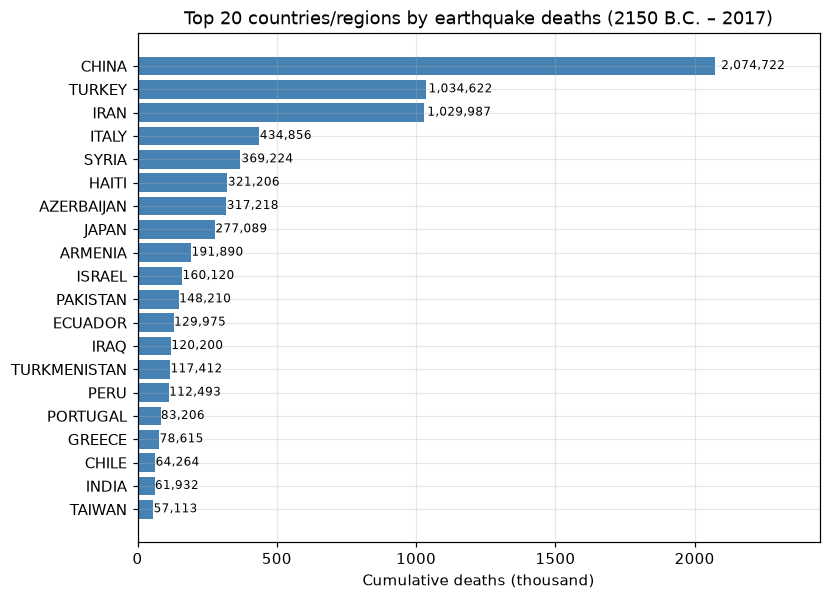

In [4]:
# 前 20 名的水平条形图(便于报告展示)
fig, ax = plt.subplots(figsize=(8, 6))
order = top20_deaths.iloc[::-1]                       # 反转让最大值在顶部
bars = ax.barh(order.index, order.values / 1e3, color="steelblue")
ax.set_xlabel("Cumulative deaths (thousand)")
ax.set_title("Top 20 countries/regions by earthquake deaths (2150 B.C. – 2017)")
# 在条形末端标注数值
for bar, v in zip(bars, order.values):
    ax.text(bar.get_width() * 1.01, bar.get_y() + bar.get_height() / 2,
            "{:,.0f}".format(v), va="center", fontsize=8)
ax.set_xlim(0, order.max() / 1e3 * 1.18)
plt.savefig(os.path.join(FIG_DIR, "p1_1_top20_deaths.png"))
plt.show()

In [5]:
# 筛选 M > 3.0 并按年计数
significant = eq.loc[eq["magnitude"] > 3.0].copy()
count_per_year = significant.groupby("year").size()

print("M > 3.0 的记录数: {} / 全部 {}".format(len(significant), len(eq)))
print("有记录的年份数: {}".format(count_per_year.size))
print("峰值年份:", int(count_per_year.idxmax()), "->", int(count_per_year.max()), "次")

M > 3.0 的记录数: 4171 / 全部 5963
有记录的年份数: 584
峰值年份: 2004 -> 77 次


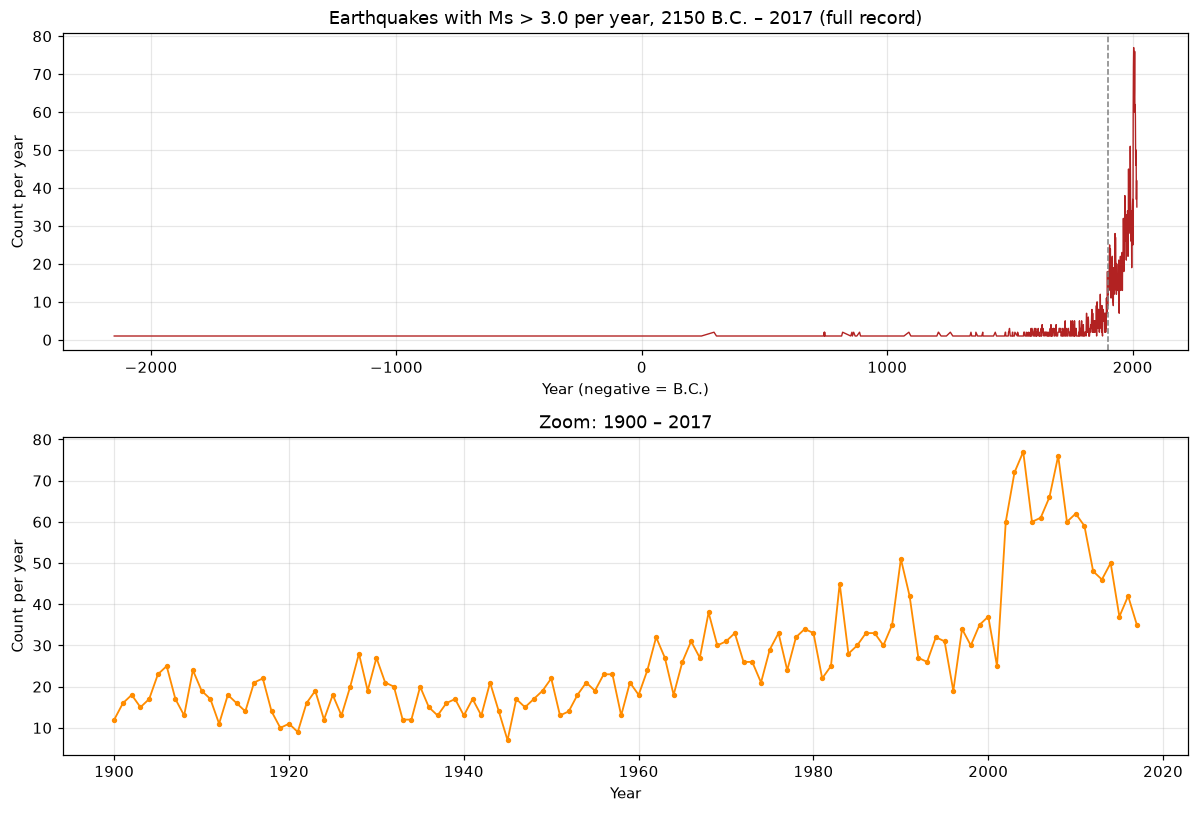

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), sharey=False)

# 上:全时段(2150 B.C. – 2017)
axes[0].plot(count_per_year.index, count_per_year.values, lw=0.9, color="firebrick")
axes[0].set_title("Earthquakes with Ms > 3.0 per year, 2150 B.C. – 2017 (full record)")
axes[0].set_xlabel("Year (negative = B.C.)")
axes[0].set_ylabel("Count per year")
axes[0].axvline(1900, color="gray", ls="--", lw=1)   # 标记台网建设起点

# 下:放大 1900 年以后
zoom = count_per_year[count_per_year.index >= 1900]
axes[1].plot(zoom.index, zoom.values, lw=1.2, marker="o", ms=2.5, color="darkorange")
axes[1].set_title("Zoom: 1900 – 2017")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Count per year")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "p1_2_count_per_year.png"))
plt.show()

In [7]:
# 定量佐证:把序列按世纪汇总,看"记录数"如何台阶式上升
by_century = (
    significant.assign(century=(significant["year"] // 100 * 100))  # 归到世纪
               .groupby("century").size()
)
print("每个世纪的记录数(最后两个世纪含观测能力跃升):")
print(by_century.tail(8).to_string())

# 同时看:有震级记录的条目占全部条目的比例,如何随年代变化
cover = (eq.assign(century=(eq["year"] // 100 * 100))
           .groupby("century")
           .apply(lambda d: d["magnitude"].notna().mean()))
print("\n各世纪'能定出震级'的记录占比:")
print((cover.tail(8) * 100).round(1).to_string())

每个世纪的记录数(最后两个世纪含观测能力跃升):
century
1300      26
1400      31
1500      62
1600     131
1700     146
1800     436
1900    2221
2000     973

各世纪'能定出震级'的记录占比:
century
1300    32.9
1400    36.5
1500    41.6
1600    42.3
1700    38.3
1800    42.7
1900    87.9
2000    99.8


In [8]:
def CountEq_LargestEq(country):
    """返回 (该国地震总数, 最大地震日期字符串, 最大地震地点字符串)。

    参数
    ----
    country : str
        国家/地区名(需与 COUNTRY 列完全一致,如 'CHINA')

    返回
    ----
    tuple 或 None
        (n_events, date_str, location_str);国家不存在时返回 None
    """
    subset = eq.loc[eq["COUNTRY"] == country]
    if subset.empty:                      # 国家名不存在
        return None

    n_events = len(subset)                # (a) 该国地震总数

    if subset["magnitude"].notna().any():
        # 有震级:取震级最大的那一行
        idx = subset["magnitude"].idxmax()
        row = subset.loc[idx]
        mag_str = "Ms={:.1f}".format(row["magnitude"])
    else:
        # 全部无震级:退化为取死亡人数最多的一条(仍可能为空),否则取第一条
        if subset["deaths"].notna().any():
            row = subset.loc[subset["deaths"].idxmax()]
        else:
            row = subset.iloc[0]
        mag_str = "no magnitude"

    # (b) 日期:处理缺失的月、日与公元前年份
    year = int(row["year"])
    month = int(row["month"]) if pd.notna(row["month"]) else None
    day = int(row["day"]) if pd.notna(row["day"]) else None
    date_str = "{}{}".format(abs(year), " B.C." if year < 0 else "")
    if month is not None:
        date_str += "-{:02d}".format(month)
        if day is not None:
            date_str += "-{:02d}".format(day)

    return n_events, date_str, "{} [{}]".format(row["name"], mag_str)


# 自测:用死亡人数最多的中国验证
print("中国:", CountEq_LargestEq("CHINA"))
print("土耳其:", CountEq_LargestEq("TURKEY"))
print("不存在的国家:", CountEq_LargestEq("ATLANTIS"))

中国: (579, '1668-07-25', 'CHINA:  SHANDONG PROVINCE [Ms=8.5]')
土耳其: (310, '1912-08-09', 'TURKEY:  MARMARA SEA [Ms=7.8]')
不存在的国家: None


In [9]:
# 对所有国家应用该函数,整理成表并按地震总数降序
rows = []
for country in eq["COUNTRY"].dropna().unique():     # unique():每个国家只算一次
    res = CountEq_LargestEq(country)
    if res is None:
        continue
    n_events, date_str, loc_str = res
    rows.append({"Country": country,
                 "N_earthquakes": n_events,
                 "Date_of_largest": date_str,
                 "Location_of_largest": loc_str})

summary = (pd.DataFrame(rows)
             .sort_values("N_earthquakes", ascending=False)  # 题目要求降序
             .reset_index(drop=True))
summary.index = summary.index + 1                            # 排名从 1 开始

print("共统计 {} 个国家/地区,地震总数合计 {} 条".format(len(summary), summary["N_earthquakes"].sum()))
print("\n按地震总数降序(前 30 名):")
print(summary.head(30).to_string())

# 完整结果存盘,附在作业仓库里便于核查
summary.to_csv(os.path.join(FIG_DIR, "..", "p1_3_country_summary.csv"), encoding="utf-8-sig")

共统计 340 个国家/地区,地震总数合计 5962 条

按地震总数降序(前 30 名):
             Country  N_earthquakes Date_of_largest                                            Location_of_largest
1              CHINA            579      1668-07-25                             CHINA:  SHANDONG PROVINCE [Ms=8.5]
2               IRAN            363       856-12-22                                 IRAN:  DAMGHAN, QUMIS [Ms=7.9]
3          INDONESIA            346      2004-12-26           INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST [Ms=9.1]
4              JAPAN            341      2011-03-11                                        JAPAN:  HONSHU [Ms=9.1]
5              ITALY            323      1915-01-13                    ITALY:  MARSICA, AVEZZANO, ABRUZZI [Ms=7.5]
6             TURKEY            310      1912-08-09                                  TURKEY:  MARMARA SEA [Ms=7.8]
7             GREECE            243       365-07-21                              GREECE:  CRETE:  KNOSSOS [Ms=8.0]
8        PHILIPPINES            2

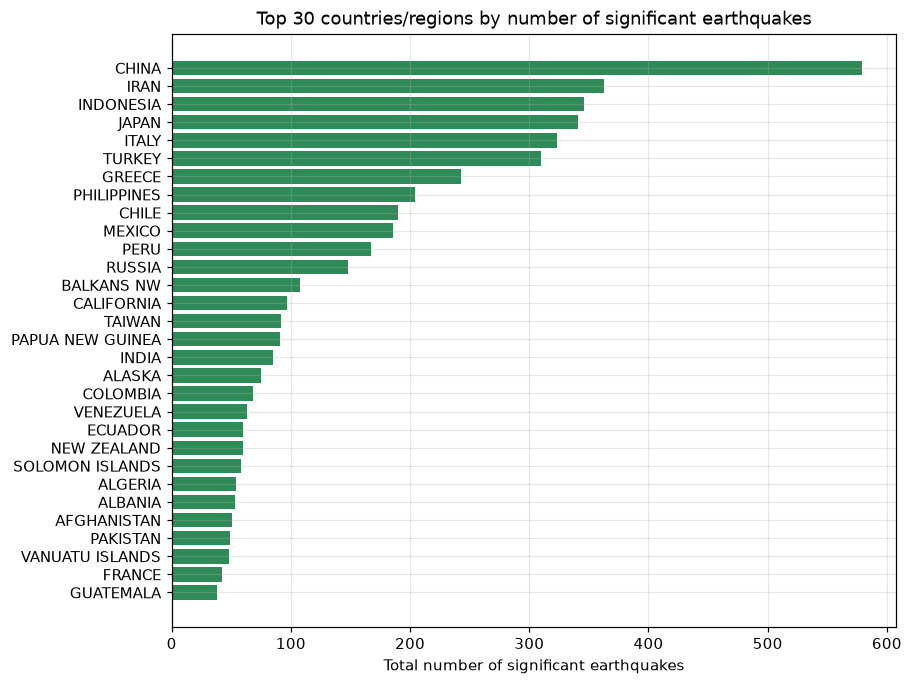

In [10]:
# 前 30 名的地震数量条形图
top30 = summary.head(30)
fig, ax = plt.subplots(figsize=(8.5, 7))
ax.barh(top30["Country"][::-1], top30["N_earthquakes"][::-1], color="seagreen")
ax.set_xlabel("Total number of significant earthquakes")
ax.set_title("Top 30 countries/regions by number of significant earthquakes")
plt.savefig(os.path.join(FIG_DIR, "p1_3_top30_counts.png"))
plt.show()

In [11]:
# ===== 环境 =====
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
DATA_DIR, FIG_DIR = "data", "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# ===== 读入(只取需要的 3 列,81 MB 文件不必整表载入) =====
df = pd.read_csv(
    os.path.join(DATA_DIR, "Baoan_Weather_1998_2022.csv"),
    usecols=["DATE", "REPORT_TYPE", "TMP"],   # 只要时间、报文类型、气温
    low_memory=False,
)
print("原始记录数:", len(df))

原始记录数: 235674


In [12]:
# ===== 解析 TMP 字段 =====
# "值,质量码" → 两列
tmp_parts = df["TMP"].str.split(",", expand=True)
df["tenths"] = pd.to_numeric(tmp_parts[0], errors="coerce")   # 原始整数,单位 0.1 °C
df["qc"] = pd.to_numeric(tmp_parts[1], errors="coerce")       # 质量码

# 单位换算:0.1 °C → °C
df["T_c"] = df["tenths"] / 10.0

print("质量码分布:")
print(df["qc"].value_counts(dropna=False).to_string())
print("\n原始值极值(0.1 °C):", df["tenths"].min(), "~", df["tenths"].max())
print("+9999 哨兵值条数:", int((df["tenths"] == 9999).sum()))

质量码分布:
qc
1    234863
9       797
2        13
5         1

原始值极值(0.1 °C): 18 ~ 9999
+9999 哨兵值条数: 797


In [13]:
# ===== 逐步清洗,并记录每一步删掉多少行 =====
n0 = len(df)

# (1) 时间列转为 datetime,作为索引
df["time"] = pd.to_datetime(df["DATE"])
df = df.dropna(subset=["time"])

# (2) 质量码过滤:只保留 1(通过全部 QC);剔除 2 可疑、5 可靠性不足、9 缺测
df = df.loc[df["qc"] == 1]
n1 = len(df)

# (3) 缺测哨兵:±9999 不是真实温度
df = df.loc[~df["tenths"].isin([9999, -9999])]
n2 = len(df)

# (4) 物理范围检查:深圳属亚热带,地面气温长期不会超出 [-5, 45] °C
df = df.loc[(df["T_c"] >= -5) & (df["T_c"] <= 45)]
n3 = len(df)

print("清洗漏斗:")
print("  原始记录            : {:,}".format(n0))
print("  剔除质量码非 1      : {:,}   (删除 {:,})".format(n1, n0 - n1))
print("  剔除 ±9999 哨兵值   : {:,}   (删除 {:,})".format(n2, n1 - n2))
print("  剔除超出物理范围    : {:,}   (删除 {:,})".format(n3, n2 - n3))
print("  最终有效记录        : {:,}  ({:.2f}%)".format(n3, 100 * n3 / n0))

清洗漏斗:
  原始记录            : 235,674
  剔除质量码非 1      : 234,863   (删除 811)
  剔除 ±9999 哨兵值   : 234,863   (删除 0)
  剔除超出物理范围    : 234,863   (删除 0)
  最终有效记录        : 234,863  (99.66%)


In [14]:
# ===== 合并同一小时的重复报文,建立逐时时间序列 =====
# 同一时间戳可能有 FM-15 与 SY-MT 两条,取平均后每个小时只留一个值
hourly = (df.set_index("time")["T_c"]
            .groupby(level=0)          # 按时间戳分组
            .mean()                    # 组内平均(通常是同值的两次报文)
            .sort_index())             # 按时间排序

print("逐时序列长度:", len(hourly))
print("时间范围:", hourly.index.min(), "→", hourly.index.max())

逐时序列长度: 212131
时间范围: 1998-01-01 00:00:00 → 2022-10-10 23:00:00


In [15]:
# ===== 计算月平均,并标记观测不足的月份 =====
monthly = pd.DataFrame({
    "T_mean": hourly.resample("MS").mean(),               # 逐时平均 → 月平均
    "n_obs": hourly.resample("MS").count(),               # 该月有效小时数
})

# 每个月的"应有小时数"(按日历天数 × 24,闰年正确处理)
days_in_month = monthly.index.days_in_month
monthly["hours_expected"] = days_in_month * 24
monthly["coverage"] = monthly["n_obs"] / monthly["hours_expected"]   # 覆盖率

# 覆盖率不足 50% 的月份视为不可靠,剔除(主要影响 1998-01 之前与 2022-10)
bad_months = monthly.loc[monthly["coverage"] < 0.5]
print("覆盖率 < 50% 而被剔除的月份:")
print(bad_months[["n_obs", "hours_expected", "coverage"]].to_string())

monthly_clean = monthly.loc[monthly["coverage"] >= 0.5].copy()
print("\n保留月份数:", len(monthly_clean))
print("平均月覆盖率: {:.1%}".format(monthly_clean["coverage"].mean()))

覆盖率 < 50% 而被剔除的月份:
            n_obs  hours_expected  coverage
time                                       
2022-10-01    239             744  0.321237

保留月份数: 297
平均月覆盖率: 97.7%


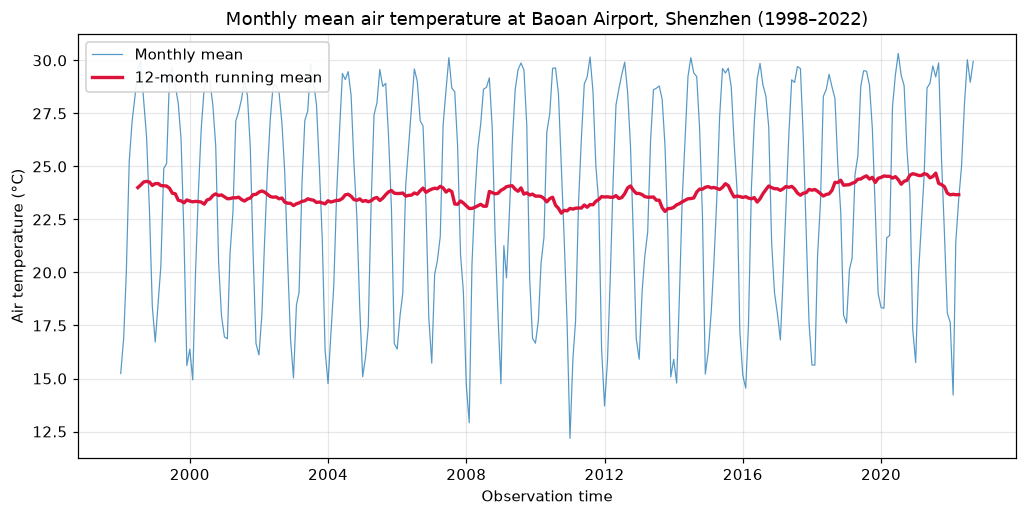

In [16]:
# ===== 画月平均气温序列 =====
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(monthly_clean.index, monthly_clean["T_mean"],
        lw=0.8, color="tab:blue", alpha=0.75, label="Monthly mean")
# 12 个月滑动平均:削弱季节循环与年际噪声
ax.plot(monthly_clean.index,
        monthly_clean["T_mean"].rolling(12, center=True).mean(),
        lw=2.2, color="crimson", label="12-month running mean")

ax.set_xlabel("Observation time")
ax.set_ylabel("Air temperature (°C)")
ax.set_title("Monthly mean air temperature at Baoan Airport, Shenzhen (1998–2022)")
ax.legend(loc="upper left", framealpha=0.9)
plt.savefig(os.path.join(FIG_DIR, "p2_1_monthly_temperature.png"))
plt.show()

In [17]:
# ===== 定量趋势:线性回归 =====
# 自变量:时间(年,带小数),因变量:月平均气温
t_year = monthly_clean.index.year + (monthly_clean.index.month - 0.5) / 12.0

res = stats.linregress(t_year, monthly_clean["T_mean"].values)
slope_per_decade = res.slope * 10          # 换算成 °C/10 年

print("【月平均序列回归】")
print("  斜率      : {:+.3f} °C/年  = {:+.3f} °C/10年".format(res.slope, slope_per_decade))
print("  标准误    : {:.4f}".format(res.stderr))
print("  p 值      : {:.3e}".format(res.pvalue))
print("  R²        : {:.3f}".format(res.rvalue ** 2))

# 年平均序列(减少自相关,结论更稳健)
annual = monthly_clean["T_mean"].resample("YS").mean()
annual = annual.dropna()
t_annual = annual.index.year + 0.5

res_a = stats.linregress(t_annual, annual.values)
print("\n【年平均序列回归】")
print("  斜率      : {:+.3f} °C/10年".format(res_a.slope * 10))
print("  p 值      : {:.3e}".format(res_a.pvalue))
print("  首末年温差: {:+.2f} °C  ({} → {})".format(
    annual.iloc[-1] - annual.iloc[0], annual.index[0].year, annual.index[-1].year))

【月平均序列回归】
  斜率      : +0.037 °C/年  = +0.370 °C/10年
  标准误    : 0.0407
  p 值      : 3.644e-01
  R²        : 0.003

【年平均序列回归】
  斜率      : +0.281 °C/10年
  p 值      : 8.268e-03
  首末年温差: +0.30 °C  (1998 → 2022)


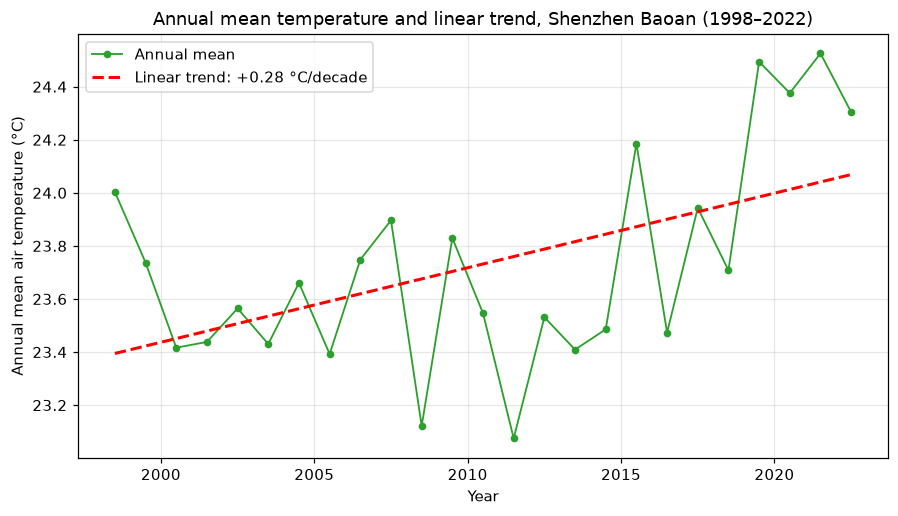

In [18]:
# ===== 年平均 + 趋势线(把"趋势"从季节循环里剥离出来) =====
fig, ax = plt.subplots(figsize=(9.5, 5))

ax.plot(annual.index.year + 0.5, annual.values, "o-", color="tab:green",
        ms=4, lw=1.2, label="Annual mean")
# 回归趋势线
ax.plot(t_annual, res_a.intercept + res_a.slope * t_annual,
        "r--", lw=2, label="Linear trend: {:+.2f} °C/decade".format(res_a.slope * 10))

ax.set_xlabel("Year")
ax.set_ylabel("Annual mean air temperature (°C)")
ax.set_title("Annual mean temperature and linear trend, Shenzhen Baoan (1998–2022)")
ax.legend()
plt.savefig(os.path.join(FIG_DIR, "p2_1_annual_trend.png"))
plt.show()

In [19]:
# ===== 补充证据:不同时段的平均气温对比 =====
# 把 1998–2022 等分成前后两段,比较两段均值差(简单而直观)
mid = monthly_clean.index[len(monthly_clean) // 2]
early = monthly_clean.loc[monthly_clean.index < mid, "T_mean"]
late = monthly_clean.loc[monthly_clean.index >= mid, "T_mean"]

print("前半段 {} – {} 平均: {:.2f} °C".format(
    early.index[0].strftime("%Y-%m"), early.index[-1].strftime("%Y-%m"), early.mean()))
print("后半段 {} – {} 平均: {:.2f} °C".format(
    late.index[0].strftime("%Y-%m"), late.index[-1].strftime("%Y-%m"), late.mean()))
print("差值: {:+.2f} °C".format(late.mean() - early.mean()))

# 逐月气候态(用于说明"季节循环远大于趋势")
clim = monthly_clean.groupby(monthly_clean.index.month)["T_mean"].mean()
print("\n逐月气候态(°C):")
print(clim.round(2).to_string())
print("季节循环振幅(最暖月 − 最冷月): {:.1f} °C".format(clim.max() - clim.min()))

前半段 1998-01 – 2010-04 平均: 23.48 °C
后半段 2010-05 – 2022-09 平均: 23.97 °C
差值: +0.49 °C

逐月气候态(°C):
time
1     15.87
2     17.21
3     19.98
4     23.52
5     26.76
6     28.57
7     29.44
8     29.23
9     28.56
10    26.00
11    22.02
12    17.34
季节循环振幅(最暖月 − 最冷月): 13.6 °C


In [20]:
# ===== 敏感性检验:不剔除任何记录(只去掉 ±9999)时的斜率 =====
raw_all = df.set_index("time")["T_c"].groupby(level=0).mean().sort_index()
raw_all = raw_all.loc[raw_all.index < pd.Timestamp("2022-10-01")]     # 去掉不完整的末月
monthly_raw = raw_all.resample("MS").mean()
t_raw = monthly_raw.index.year + (monthly_raw.index.month - 0.5) / 12.0
res_raw = stats.linregress(t_raw, monthly_raw.values)

print("敏感性检验(不做质量码/范围过滤):")
print("  斜率 {:.3f} °C/10年,p = {:.2e}".format(res_raw.slope * 10, res_raw.pvalue))
print("  与清洗后结果差异: {:.3f} °C/10年".format(res_raw.slope * 10 - slope_per_decade))

敏感性检验(不做质量码/范围过滤):
  斜率 0.370 °C/10年,p = 3.64e-01
  与清洗后结果差异: 0.000 °C/10年


In [21]:
# ===== 环境 =====
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
DATA_DIR, FIG_DIR = "data", "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# ===== 读入 =====
raw = pd.read_csv(
    os.path.join(DATA_DIR, "ibtracs.ALL.list.v04r00.csv"),
    usecols=range(17),                        # 只读前 17 列,控制内存
    skiprows=[1],                             # 只跳过第 2 行的"单位"行(原示例多跳了一行数据)
    parse_dates=["ISO_TIME"],                 # 时间列直接解析为 datetime
    na_values=["NOT_NAMED", "NAME", "", " "], # 未命名风暴与空格视为缺失
    keep_default_na=False,                    # 关键:'NA'=北大西洋,不能被当成缺失值
    low_memory=False,
)
print("总行数:", len(raw))
print("列名:", list(raw.columns))

总行数: 707177
列名: ['SID', 'SEASON', 'NUMBER', 'BASIN', 'SUBBASIN', 'NAME', 'ISO_TIME', 'NATURE', 'LAT', 'LON', 'WMO_WIND', 'WMO_PRES', 'WMO_AGENCY', 'TRACK_TYPE', 'DIST2LAND', 'LANDFALL', 'IFLAG']


In [22]:
# ===== 类型转换 =====
for col in ["WMO_WIND", "LAT", "LON", "SEASON"]:
    raw[col] = pd.to_numeric(raw[col], errors="coerce")   # 空串 → NaN

# 只保留主路径,避免同一时次被 spur 路径重复计数
df = raw.loc[raw["TRACK_TYPE"] == "main"].copy()

print("\n主路径记录数: {:,} (占 {:.1%})".format(len(df), len(df) / len(raw)))
print("风暴数(SID):", df["SID"].nunique())
print("时间范围:", df["ISO_TIME"].min(), "→", df["ISO_TIME"].max())
print("\n各盆地记录数:")
print(df["BASIN"].value_counts(dropna=False).to_string())
print("\nWMO_WIND 有效记录: {:,} ({:.1%})".format(df["WMO_WIND"].notna().sum(),
                                              df["WMO_WIND"].notna().mean()))


主路径记录数: 682,158 (占 96.5%)
风暴数(SID): 12746
时间范围: 1842-10-25 03:00:00 → 2021-11-10 12:00:00

各盆地记录数:
BASIN
WP    230512
SI    148936
NA    121977
SP     64582
EP     61037
NI     54995
SA       119

WMO_WIND 有效记录: 152,590 (22.4%)


In [23]:
# 每个风暴的最大 WMO 风速,同时保留它的名字、年份、盆地
storm_max = (df.groupby("SID")
               .agg(name=("NAME", "first"),        # 风暴名
                    season=("SEASON", "first"),    # 年份
                    basin=("BASIN", "first"),      # 盆地
                    wmax=("WMO_WIND", "max"))      # 生命史内最大风速
               .dropna(subset=["wmax"]))           # 剔除整条无风速记录的风暴

top10 = storm_max.sort_values("wmax", ascending=False).head(10)

print("风速最大的 10 个飓风(单位:knots)\n" + "-" * 62)
print("{:<4}{:<14}{:<8}{:<6}{:>10}".format("排名", "名称", "年份", "盆地", "最大风速"))
print("-" * 62)
for i, (sid, row) in enumerate(top10.iterrows(), start=1):
    name = row["name"] if pd.notna(row["name"]) else "(unnamed)"
    print("{:<4}{:<14}{:<8}{:<6}{:>10.0f}".format(i, name, int(row["season"]), row["basin"], row["wmax"]))

风速最大的 10 个飓风(单位:knots)
--------------------------------------------------------------
排名  名称            年份      盆地          最大风速
--------------------------------------------------------------
1   PATRICIA      2015    EP           185
2   ALLEN         1980    NA           165
3   DORIAN        2019    NA           160
4   (unnamed)     1935    NA           160
5   LINDA         1997    EP           160
6   GILBERT       1988    NA           160
7   WILMA         2005    NA           160
8   IRMA          2017    NA           155
9   MITCH         1998    NA           155
10  RITA          2005    NA           155


In [24]:
# 直接对轨迹点的风速排序(不是按风暴聚合)
top20_points = df.nlargest(20, "WMO_WIND")[["SID", "NAME", "SEASON", "ISO_TIME", "BASIN", "WMO_WIND"]]

print("最强 20 个轨迹点的 WMO 风速(knots):")
print(top20_points.to_string(index=False))
print("\n其中来自 {} 条不同的风暴".format(top20_points["SID"].nunique()))

最强 20 个轨迹点的 WMO 风速(knots):
          SID     NAME  SEASON            ISO_TIME BASIN  WMO_WIND
2015293N13266 PATRICIA    2015 2015-10-23 12:00:00    EP     185.0
2015293N13266 PATRICIA    2015 2015-10-23 06:00:00    EP     180.0
2015293N13266 PATRICIA    2015 2015-10-23 18:00:00    EP     180.0
1980214N11330    ALLEN    1980 1980-08-07 18:00:00    NA     165.0
1935241N23291      NaN    1935 1935-09-03 00:00:00    NA     160.0
1935241N23291      NaN    1935 1935-09-03 02:00:00    NA     160.0
1935241N23291      NaN    1935 1935-09-03 06:00:00    NA     160.0
1988253N12306  GILBERT    1988 1988-09-14 00:00:00    NA     160.0
1997253N12255    LINDA    1997 1997-09-12 06:00:00    EP     160.0
2005289N18282    WILMA    2005 2005-10-19 12:00:00    NA     160.0
2019236N10314   DORIAN    2019 2019-09-01 16:40:00    NA     160.0
2019236N10314   DORIAN    2019 2019-09-01 18:00:00    NA     160.0
1980214N11330    ALLEN    1980 1980-08-05 12:00:00    NA     155.0
1980214N11330    ALLEN    1980 1980

In [25]:
basin_counts = df["BASIN"].value_counts(dropna=False)
print("各盆地轨迹点数量:")
print(basin_counts.to_string())
print("\n合计: {:,}".format(basin_counts.sum()))

各盆地轨迹点数量:
BASIN
WP    230512
SI    148936
NA    121977
SP     64582
EP     61037
NI     54995
SA       119

合计: 682,158


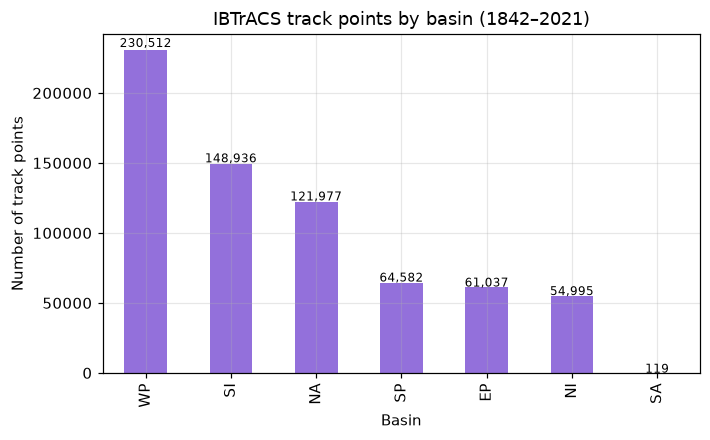

In [26]:
# 盆地计数柱状图
fig, ax = plt.subplots(figsize=(7, 4))
basin_counts.plot(kind="bar", ax=ax, color="mediumpurple")
ax.set_xlabel("Basin")
ax.set_ylabel("Number of track points")
ax.set_title("IBTrACS track points by basin (1842–2021)")
for i, v in enumerate(basin_counts.values):
    ax.text(i, v * 1.01, "{:,}".format(v), ha="center", fontsize=8)
plt.savefig(os.path.join(FIG_DIR, "p3_3_basin_counts.png"))
plt.show()

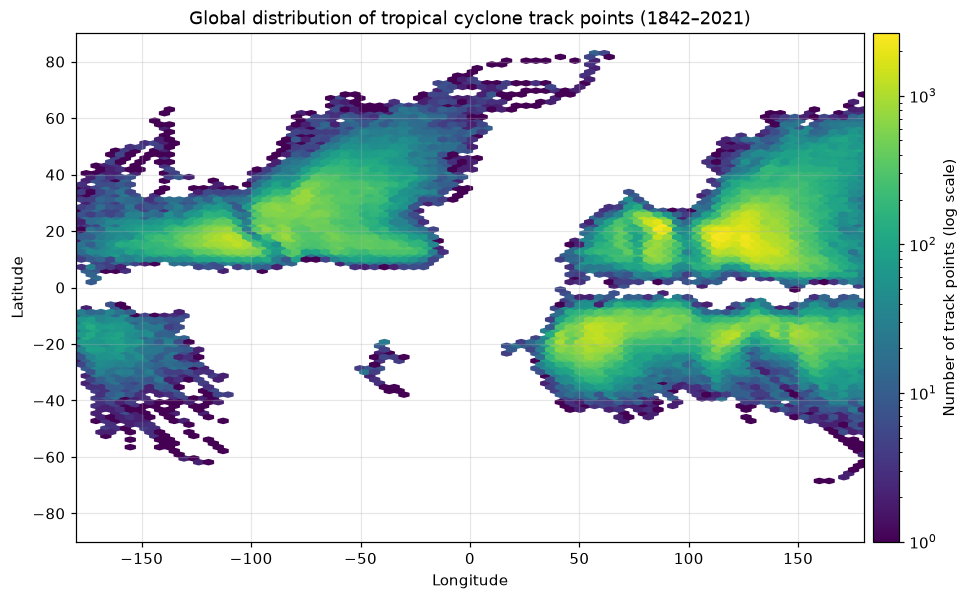

In [27]:
fig, ax = plt.subplots(figsize=(11, 6))
hb = ax.hexbin(df["LON"], df["LAT"],
               gridsize=100,             # 六边形网格密度
               norm=LogNorm(),           # 对数色标:兼顾高密度与低密度区
               cmap="viridis", mincnt=1) # mincnt=1:至少 1 个点才着色
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Global distribution of tropical cyclone track points (1842–2021)")
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
cb = fig.colorbar(hb, ax=ax, pad=0.01)
cb.set_label("Number of track points (log scale)")
plt.savefig(os.path.join(FIG_DIR, "p3_4_hexbin.png"))
plt.show()

In [28]:
# 筛选 2018 年山竹
mg = df.loc[(df["NAME"].astype(str).str.upper() == "MANGKHUT") & (df["SEASON"] == 2018)]
mg = mg.sort_values("ISO_TIME")

print("山竹记录数:", len(mg))
print("时间范围:", mg["ISO_TIME"].min(), "→", mg["ISO_TIME"].max())
print("路径范围: 纬度 {:.1f}–{:.1f},经度 {:.1f}–{:.1f}".format(
    mg["LAT"].min(), mg["LAT"].max(), mg["LON"].min(), mg["LON"].max()))
print("最大 WMO 风速: {} knots".format(mg["WMO_WIND"].max()))
print("有风速记录的时次: {} / {}".format(mg["WMO_WIND"].notna().sum(), len(mg)))

山竹记录数: 99
时间范围: 2018-09-06 12:00:00 → 2018-09-17 18:00:00
路径范围: 纬度 11.8–24.1,经度 103.9–170.2
最大 WMO 风速: 110.0 knots
有风速记录的时次: 39 / 99


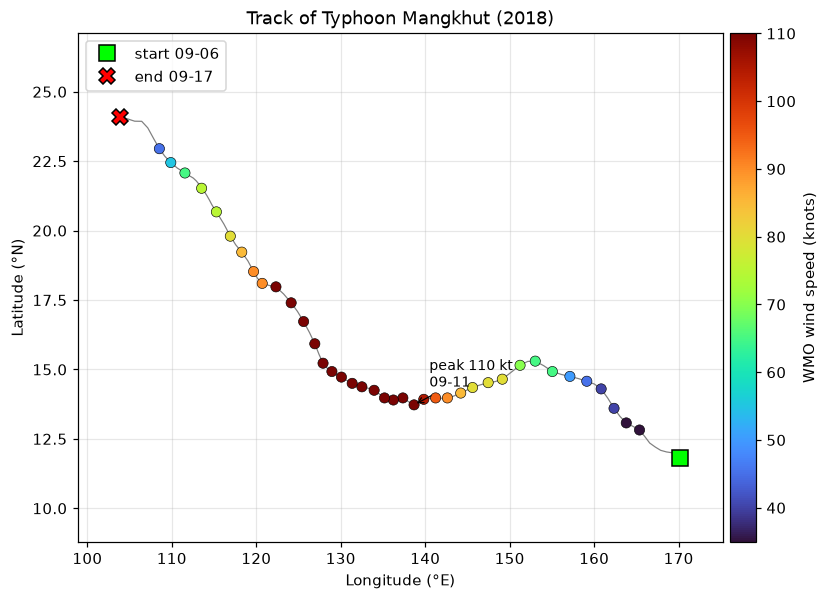

In [29]:
fig, ax = plt.subplots(figsize=(9, 6))

# 若有风速就用颜色编码,否则退化为单色路径
if mg["WMO_WIND"].notna().any():
    sc = ax.scatter(mg["LON"], mg["LAT"], c=mg["WMO_WIND"], cmap="turbo",
                    s=45, edgecolor="k", linewidth=0.4, zorder=3)
    cb = fig.colorbar(sc, ax=ax, pad=0.01)
    cb.set_label("WMO wind speed (knots)")
    ax.plot(mg["LON"], mg["LAT"], color="gray", lw=0.8, zorder=2)
else:
    ax.plot(mg["LON"], mg["LAT"], "o-", color="tab:red")

# 标出起点与终点
ax.plot(mg["LON"].iloc[0], mg["LAT"].iloc[0], "s", ms=10, color="lime",
        markeredgecolor="k", label="start " + mg["ISO_TIME"].iloc[0].strftime("%m-%d"), zorder=4)
ax.plot(mg["LON"].iloc[-1], mg["LAT"].iloc[-1], "X", ms=11, color="red",
        markeredgecolor="k", label="end " + mg["ISO_TIME"].iloc[-1].strftime("%m-%d"), zorder=4)

# 标注强度峰值位置
if mg["WMO_WIND"].notna().any():
    pk = mg.loc[mg["WMO_WIND"].idxmax()]
    ax.annotate("peak {:.0f} kt\n{}".format(pk["WMO_WIND"], pk["ISO_TIME"].strftime("%m-%d")),
                xy=(pk["LON"], pk["LAT"]), xytext=(10, 12), textcoords="offset points",
                fontsize=9, arrowprops=dict(arrowstyle="->", lw=0.8))

ax.set_xlabel("Longitude (°E)")
ax.set_ylabel("Latitude (°N)")
ax.set_title("Track of Typhoon Mangkhut (2018)")
ax.legend(loc="upper left")
ax.set_xlim(mg["LON"].min() - 5, mg["LON"].max() + 5)
ax.set_ylim(mg["LAT"].min() - 3, mg["LAT"].max() + 3)
plt.savefig(os.path.join(FIG_DIR, "p3_5_mangkhut.png"))
plt.show()

In [30]:
# 双重筛选:年份 + 盆地
wp_ep = df.loc[(df["SEASON"] >= 1970) & (df["BASIN"].isin(["WP", "EP"]))].copy()

print("子集记录数: {:,}".format(len(wp_ep)))
print("子集风暴数: {:,}".format(wp_ep["SID"].nunique()))
print("时间范围:", wp_ep["ISO_TIME"].min(), "→", wp_ep["ISO_TIME"].max())
print("\n盆地构成:")
print(wp_ep["BASIN"].value_counts().to_string())

子集记录数: 170,487
子集风暴数: 2,713
时间范围: 1970-02-19 00:00:00 → 2021-11-10 12:00:00

盆地构成:
BASIN
WP    117774
EP     52713


In [31]:
# 每天的点数
daily = (wp_ep.set_index("ISO_TIME")
              .resample("D")        # 按自然日重采样
              .size())              # 每天的行数
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max(), freq="D"),
                      fill_value=0)     # 补齐缺口日为 0

print("覆盖天数:", len(daily))
print("平均每天点数: {:.1f}".format(daily.mean()))
print("有观测的天数: {:,} ({:.1%})".format((daily > 0).sum(), (daily > 0).mean()))

覆盖天数: 18893
平均每天点数: 9.0
有观测的天数: 10,575 (56.0%)


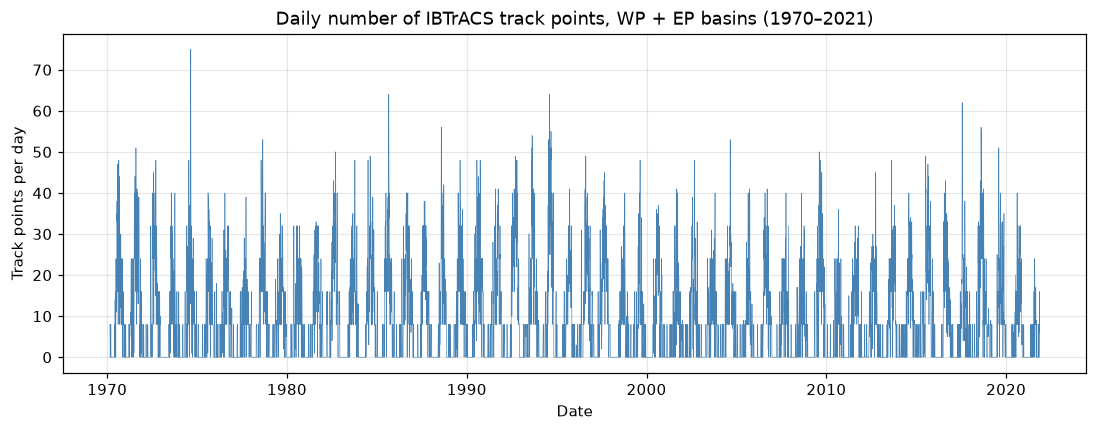

In [32]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily.values, lw=0.4, color="steelblue")
ax.set_xlabel("Date")
ax.set_ylabel("Track points per day")
ax.set_title("Daily number of IBTrACS track points, WP + EP basins (1970–2021)")
plt.savefig(os.path.join(FIG_DIR, "p3_7_daily_counts.png"))
plt.show()

In [33]:
# ===== 只保留完整年,并构造统一的 1–365 年积日 =====
daily_full = daily.loc["1971-01-01":"2020-12-31"]        # 50 个完整年

# 剔除 2 月 29 日
mask_not_leapday = ~((daily_full.index.month == 2) & (daily_full.index.day == 29))
d = daily_full.loc[mask_not_leapday]

# 闰年 3 月 1 日及以后,DOY 减 1,使所有年份统一为 1–365
is_after_feb = (d.index.is_leap_year) & (d.index.dayofyear > 59)
doy_fixed = d.index.dayofyear - is_after_feb.astype(int)

print("参与气候态统计的天数:", len(d))
print("统一后的年积日范围: {} – {}".format(doy_fixed.min(), doy_fixed.max()))
print("唯一 DOY 个数(应为 365):", len(pd.unique(doy_fixed)))

# 按统一 DOY 分组求多年平均
climatology = d.groupby(doy_fixed).mean()

print("\n气候态长度:", len(climatology))
print("气候态峰值: DOY={} ({:.1f} 点/天)".format(climatology.idxmax(), climatology.max()))
print("气候态谷值: DOY={} ({:.1f} 点/天)".format(climatology.idxmin(), climatology.min()))

peak_doy = int(climatology.idxmax())
print("峰值日期约为: 第 {} 天 ≈ {}".format(
    peak_doy, (pd.Timestamp("2001-01-01") + pd.Timedelta(days=peak_doy - 1)).strftime("%m-%d")))

参与气候态统计的天数: 18250
统一后的年积日范围: 1 – 365
唯一 DOY 个数(应为 365): 365

气候态长度: 365
气候态峰值: DOY=222 (26.8 点/天)
气候态谷值: DOY=55 (0.2 点/天)
峰值日期约为: 第 222 天 ≈ 08-10


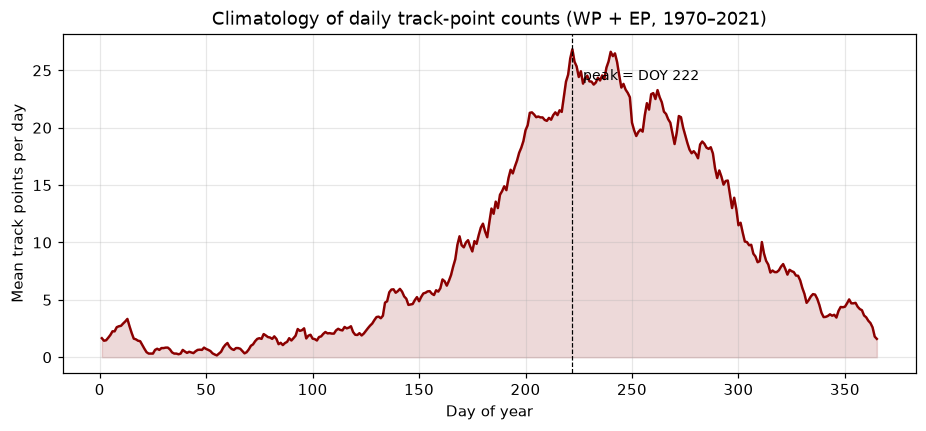

In [34]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(climatology.index, climatology.values, color="darkred", lw=1.6)
ax.fill_between(climatology.index, 0, climatology.values, color="darkred", alpha=0.15)
ax.set_xlabel("Day of year")
ax.set_ylabel("Mean track points per day")
ax.set_title("Climatology of daily track-point counts (WP + EP, 1970–2021)")
ax.axvline(peak_doy, color="k", ls="--", lw=0.8)
ax.text(peak_doy + 5, climatology.max() * 0.9, "peak = DOY {}".format(peak_doy), fontsize=9)
plt.savefig(os.path.join(FIG_DIR, "p3_8_climatology.png"))
plt.show()

In [35]:
# 用统一后的年积日把气候态映射到每一天
clim_by_doy = climatology.to_dict()
anomaly = d - pd.Series(doy_fixed, index=d.index).map(clim_by_doy).astype(float)

print("距平序列长度:", len(anomaly))
print("距平均值 {:.4f}(应接近 0)".format(anomaly.mean()))
print("距平标准差: {:.3f}".format(anomaly.std()))
print("最大正距平: {} ({:+.1f})".format(anomaly.idxmax().date(), anomaly.max()))
print("最大负距平: {} ({:+.1f})".format(anomaly.idxmin().date(), anomaly.min()))

距平序列长度: 18250
距平均值 -0.0000(应接近 0)
距平标准差: 7.241
最大正距平: 1974-08-26 (+49.8)
最大负距平: 1977-08-30 (-26.5)


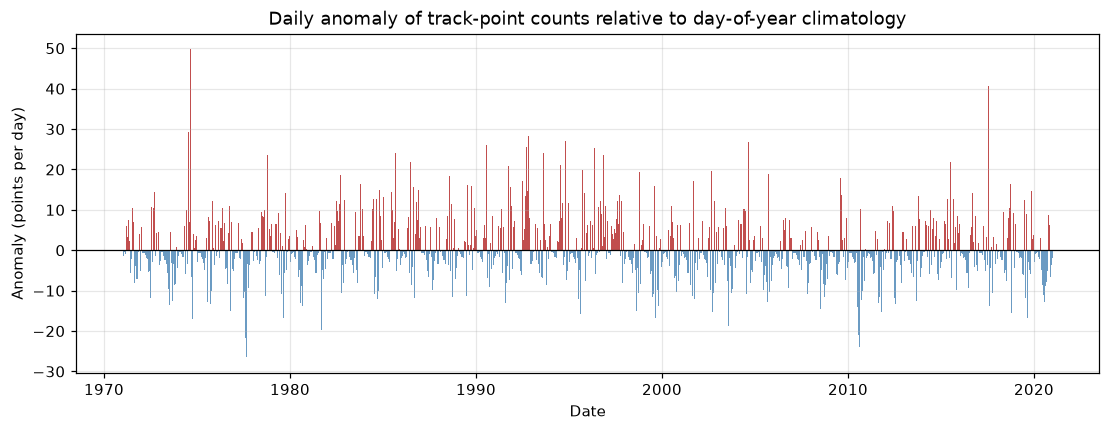

In [36]:
# 距平序列(正=比常年活跃,负=比常年沉寂)
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(anomaly.index, anomaly.values, width=1.0,
       color=np.where(anomaly.values >= 0, "firebrick", "steelblue"), alpha=0.8)
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Date")
ax.set_ylabel("Anomaly (points per day)")
ax.set_title("Daily anomaly of track-point counts relative to day-of-year climatology")
plt.savefig(os.path.join(FIG_DIR, "p3_9_anomaly.png"))
plt.show()

In [37]:
# 日距平 → 年累积距平
annual_anom = anomaly.resample("YS").sum()
annual_anom = annual_anom.dropna()

# 标准化,便于跨年份比较
z = (annual_anom - annual_anom.mean()) / annual_anom.std()

result = pd.DataFrame({
    "annual_anomaly": annual_anom,
    "z_score": z,
}).sort_values("z_score", ascending=False)

print("最活跃的 5 年(正异常最大):")
print(result.head(5).round(2).to_string())
print("\n最沉寂的 5 年(负异常最大):")
print(result.tail(5).round(2).to_string())
print("\n|z| > 1 的年份:", list(result.index[result["z_score"].abs() > 1].year))

最活跃的 5 年(正异常最大):
            annual_anomaly  z_score
1992-01-01         1535.72     2.15
1994-01-01         1399.72     1.96
2015-01-01         1139.72     1.59
1990-01-01         1094.72     1.53
1997-01-01         1075.72     1.50

最沉寂的 5 年(负异常最大):
            annual_anomaly  z_score
2007-01-01         -915.28    -1.28
1973-01-01         -922.28    -1.29
1977-01-01         -995.28    -1.39
1998-01-01        -1013.28    -1.42
2010-01-01        -1648.28    -2.30

|z| > 1 的年份: [1992, 1994, 2015, 1990, 1997, 1971, 1985, 1993, 1986, 2011, 2020, 1999, 2007, 1973, 1977, 1998, 2010]


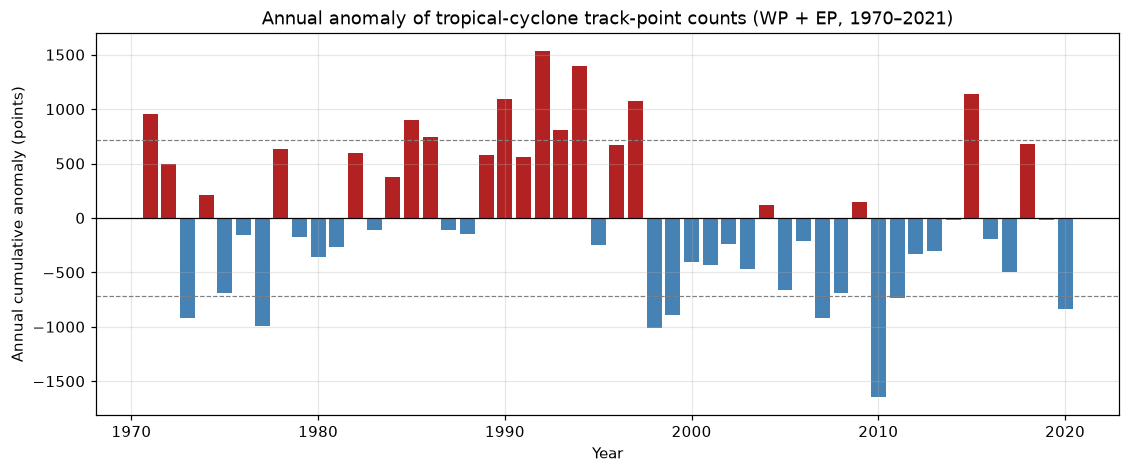

In [38]:
fig, ax = plt.subplots(figsize=(12, 4.5))
colors = ["firebrick" if v >= 0 else "steelblue" for v in annual_anom.values]
ax.bar(annual_anom.index.year, annual_anom.values, color=colors, width=0.8)
ax.axhline(0, color="k", lw=0.8)
# 用虚线标出 ±1 标准差
sd = annual_anom.std()
ax.axhline(sd, color="gray", ls="--", lw=0.8)
ax.axhline(-sd, color="gray", ls="--", lw=0.8)

ax.set_xlabel("Year")
ax.set_ylabel("Annual cumulative anomaly (points)")
ax.set_title("Annual anomaly of tropical-cyclone track-point counts (WP + EP, 1970–2021)")
plt.savefig(os.path.join(FIG_DIR, "p3_10_annual_anomaly.png"))
plt.show()

In [39]:
# ===== 环境 =====
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
DATA_DIR, FIG_DIR = "data", "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# ===== 4.1 读入 =====
raw = pd.read_csv(os.path.join(DATA_DIR, "CHM00055591.csv"), low_memory=False)
print("原始记录数:", len(raw))
print("站点:", raw["NAME"].iloc[0], "| 海拔: {} m".format(raw["ELEVATION"].iloc[0]))
print("时间范围:", raw["DATE"].min(), "→", raw["DATE"].max())

原始记录数: 25755
站点: LHASA, CH | 海拔: 3650.0 m
时间范围: 1955-01-01 → 2025-08-24


In [40]:
# ===== 4.1 清洗 =====
df = raw.copy()

# (1) 时间索引
df["DATE"] = pd.to_datetime(df["DATE"])
df = df.set_index("DATE").sort_index()

# (2) 解码质量标记 QFLAG(ATTRIBUTES 的第 2 位),非空则视为质控不通过
def qflag_of(attr_series):
    """从 ',,s' 这样的字符串里取出第 2 位(QFLAG)。"""
    parts = attr_series.fillna(",,,").str.split(",", expand=True)
    if parts.shape[1] < 2:
        return pd.Series("", index=attr_series.index)
    return parts[1].fillna("")

for var in ["TMAX", "TMIN", "PRCP"]:
    qf = qflag_of(df[var + "_ATTRIBUTES"])
    n_bad = (qf != "").sum()
    df.loc[qf != "", var] = np.nan          # 质控不通过 → 置为缺失
    print("{}: 因 QFLAG 非空被剔除 {} 条".format(var, n_bad))

# (3) 单位换算:0.1 °C → °C;0.1 mm → mm
for var in ["TMAX", "TMIN", "TAVG"]:
    df[var] = df[var] / 10.0
df["PRCP"] = df["PRCP"] / 10.0

# (4) 物理范围检查
before = len(df)
df.loc[(df["TMAX"] < -30) | (df["TMAX"] > 45), "TMAX"] = np.nan
df.loc[(df["TMIN"] < -45) | (df["TMIN"] > 30), "TMIN"] = np.nan
df.loc[(df["PRCP"] < 0) | (df["PRCP"] > 200), "PRCP"] = np.nan

# (5) 日均温:用 (TMAX + TMIN)/2,比 TAVG 覆盖率更高
df["TMEAN"] = (df["TMAX"] + df["TMIN"]) / 2.0

print("\n清洗后各要素缺失率:")
for var in ["TMAX", "TMIN", "PRCP", "TMEAN"]:
    print("  {:<6}: {:,} / {:,} = {:.2%}".format(
        var, df[var].isna().sum(), len(df), df[var].isna().mean()))

print("\n清洗后统计量:")
print(df[["TMAX", "TMIN", "PRCP"]].describe().round(2).to_string())

TMAX: 因 QFLAG 非空被剔除 3 条
TMIN: 因 QFLAG 非空被剔除 25 条
PRCP: 因 QFLAG 非空被剔除 7 条

清洗后各要素缺失率:
  TMAX  : 1,864 / 25,755 = 7.24%
  TMIN  : 618 / 25,755 = 2.40%
  PRCP  : 1,740 / 25,755 = 6.76%
  TMEAN : 2,030 / 25,755 = 7.88%

清洗后统计量:
           TMAX      TMIN      PRCP
count  23891.00  25137.00  24015.00
mean      16.11      1.91      1.32
std        6.40      7.58      3.92
min       -4.00    -16.50      0.00
25%       11.10     -4.60      0.00
50%       16.70      2.30      0.00
75%       21.30      8.90      0.10
max       38.80     25.20     96.50


In [41]:
# ===== 构造年平均与年总量 =====
year = df.index.year

valid_days = df["TMEAN"].notna().groupby(year).sum()          # 每年有效日数
annual_t = df["TMEAN"].groupby(year).mean()                   # 年平均气温
annual_p = df["PRCP"].groupby(year).sum(min_count=1)          # 年降水总量(mm)

# 每年至少 300 天有效才纳入年平均
annual_t = annual_t.where(valid_days >= 300)
annual_t = annual_t.dropna()

print("参与趋势分析的年份数: {}".format(len(annual_t)))
print("年份范围: {} – {}".format(annual_t.index.min(), annual_t.index.max()))
dropped = list(valid_days.index[valid_days < 300])
print("因有效天数不足 300 天而剔除的年份: {} 个 -> {}".format(len(dropped), dropped))

参与趋势分析的年份数: 63
年份范围: 1955 – 2024
因有效天数不足 300 天而剔除的年份: 8 个 -> [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2025]


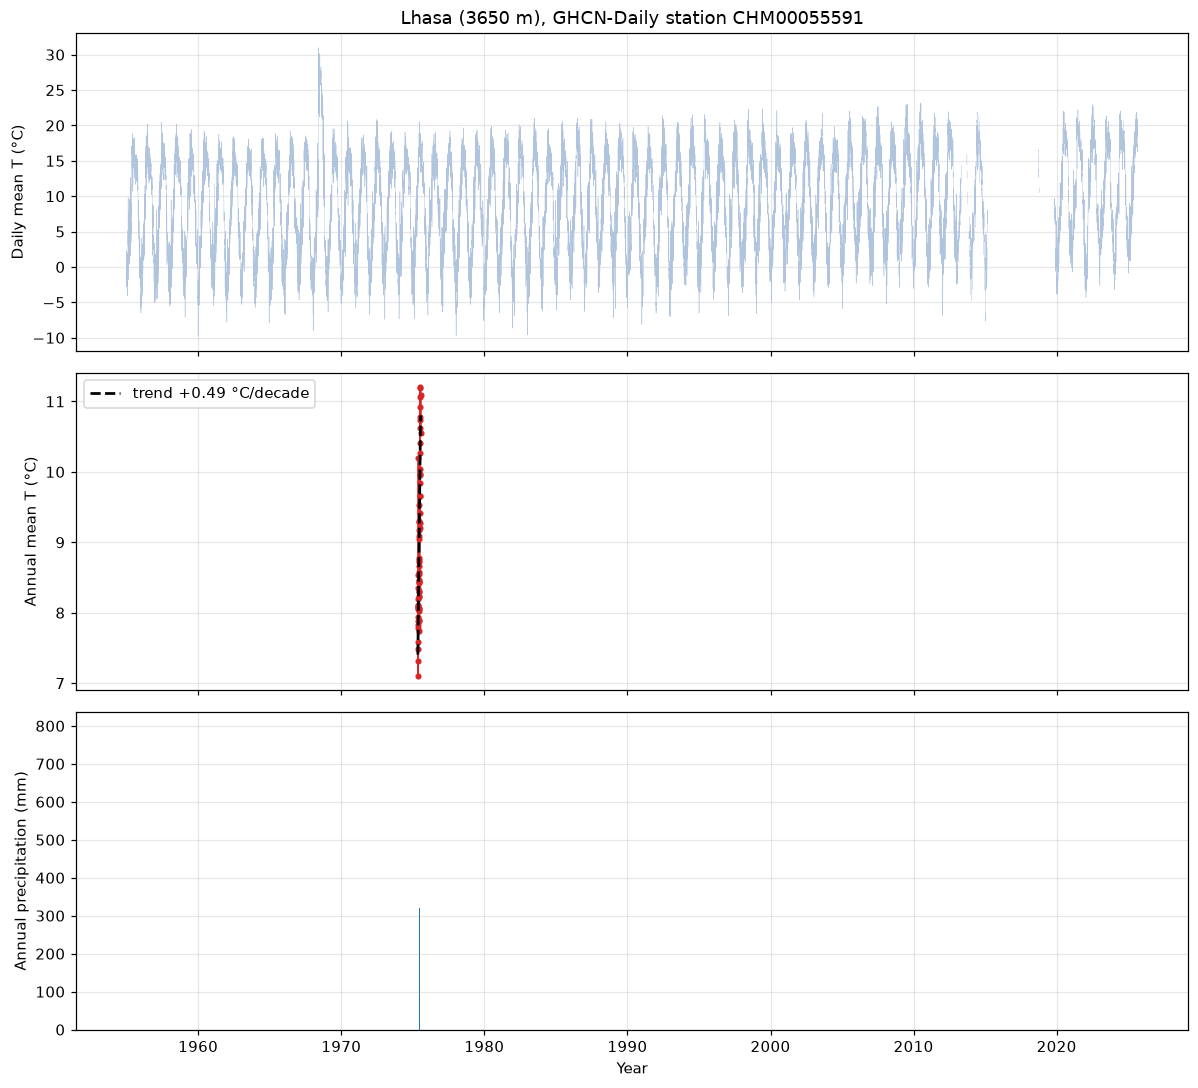

In [42]:
fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)

# (1) 逐日气温
axes[0].plot(df.index, df["TMEAN"], lw=0.3, color="lightsteelblue")
axes[0].set_ylabel("Daily mean T (°C)")
axes[0].set_title("Lhasa (3650 m), GHCN-Daily station CHM00055591")

# (2) 年均温 + 趋势
res = stats.linregress(annual_t.index.values, annual_t.values)
axes[1].plot(annual_t.index, annual_t.values, "o-", ms=3, lw=1, color="tab:red")
axes[1].plot(annual_t.index, res.intercept + res.slope * annual_t.index,
             "k--", lw=1.8, label="trend {:+.2f} °C/decade".format(res.slope * 10))
axes[1].set_ylabel("Annual mean T (°C)")
axes[1].legend(loc="upper left")

# (3) 年降水
axes[2].bar(annual_p.index, annual_p.values, color="tab:blue", width=0.8)
axes[2].set_ylabel("Annual precipitation (mm)")
axes[2].set_xlabel("Year")

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "p4_2_timeseries.png"))
plt.show()

In [43]:
# 每年有效观测天数(以日均温为基准)
per_year_valid = df["TMEAN"].notna().groupby(year).sum()
per_year_all = df["TMEAN"].groupby(year).size()
completeness = (per_year_valid / per_year_all).dropna()

print("年度数据完整率:")
print("  平均 {:.1%} | 最低 {:.1%}({}) | 最高 {:.1%}".format(
    completeness.mean(), completeness.min(), completeness.idxmin(), completeness.max()))
print("  完整率 < 80% 的年份:", list(completeness.index[completeness < 0.8]))

# 完整率与年份的相关(是否随时间改善)
r_comp = stats.pearsonr(completeness.index.values, completeness.values)
print("  完整率与年份的相关系数 r = {:.3f},p = {:.2e}".format(r_comp[0], r_comp[1]))

年度数据完整率:
  平均 92.1% | 最低 0.3%(2017) | 最高 100.0%
  完整率 < 80% 的年份: [2013, 2014, 2015, 2016, 2017, 2018, 2019]
  完整率与年份的相关系数 r = -0.401,p = 5.31e-04


In [44]:
for var, label in [("TMAX", "日最高气温"), ("PRCP", "日降水量")]:
    x = df[var].dropna()
    sk = stats.skew(x)
    ku = stats.kurtosis(x)                       # Fisher 定义,正态为 0
    k2, p_k2 = stats.normaltest(x.sample(5000, random_state=0))   # K² 检验(抽样 5000 加速)
    print("{}(n={:,}):".format(label, len(x)))
    print("  均值 {:.2f} | 标准差 {:.2f} | 偏度 {:+.2f} | 峰度 {:+.2f}".format(
        x.mean(), x.std(), sk, ku))
    print("  D'Agostino K² = {:.1f},p = {:.2e} → {}".format(
        k2, p_k2, "拒绝正态" if p_k2 < 0.05 else "不能拒绝正态"))
    print("  降水量为 0 的比例: {:.1%}".format((x == 0).mean()) if var == "PRCP" else "")

日最高气温(n=23,891):
  均值 16.11 | 标准差 6.40 | 偏度 -0.21 | 峰度 -0.71
  D'Agostino K² = 220.8,p = 1.12e-48 → 拒绝正态

日降水量(n=24,015):
  均值 1.32 | 标准差 3.92 | 偏度 +4.91 | 峰度 +39.03
  D'Agostino K² = 4461.8,p = 0.00e+00 → 拒绝正态
  降水量为 0 的比例: 73.4%


In [45]:
monthly_groups = [df.loc[df.index.month == m, "TMEAN"].dropna() for m in range(1, 13)]
f_stat, p_anova = stats.f_oneway(*monthly_groups)

print("单因素方差分析(按月份分组):")
print("  F = {:.1f},p = {:.2e} → {}".format(
    f_stat, p_anova, "季节循环极显著" if p_anova < 1e-10 else "不显著"))

monthly_clim = df["TMEAN"].groupby(df.index.month).mean()
print("\n各月气候态(°C):")
print(monthly_clim.round(2).to_string())
print("季节振幅(最暖月 − 最冷月): {:.1f} °C".format(monthly_clim.max() - monthly_clim.min()))

单因素方差分析(按月份分组):
  F = 11770.1,p = 0.00e+00 → 季节循环极显著

各月气候态(°C):
DATE
1     -0.42
2      1.95
3      5.46
4      8.97
5     13.02
6     16.91
7     16.88
8     16.02
9     14.38
10     9.91
11     4.26
12     0.49
季节振幅(最暖月 − 最冷月): 17.3 °C


In [46]:
def mann_kendall(x):
    """Mann-Kendall 趋势检验。返回 (S 统计量, 标准化 Z, 双侧 p 值)。"""
    x = np.asarray(x, dtype=float)
    n = len(x)
    s = 0.0
    for k in range(n - 1):
        s += np.sum(np.sign(x[k + 1:] - x[k]))          # 后面每个点与当前点比较
    # 方差(考虑结/ties 的修正)
    _, counts = np.unique(x, return_counts=True)
    var_s = (n * (n - 1) * (2 * n + 5) - np.sum(counts * (counts - 1) * (2 * counts + 5))) / 18.0
    if s > 0:
        z = (s - 1) / np.sqrt(var_s)
    elif s < 0:
        z = (s + 1) / np.sqrt(var_s)
    else:
        z = 0.0
    p = 2 * (1 - stats.norm.cdf(abs(z)))                # 双侧检验
    return s, z, p


def sens_slope(x):
    """Sen's slope:所有点对斜率的中位数(单位与 x 的步长一致)。"""
    x = np.asarray(x, dtype=float)
    n = len(x)
    slopes = []
    for i in range(n - 1):
        slopes.append((x[i + 1:] - x[i]) / np.arange(1, n - i))
    return np.median(np.concatenate(slopes))


# --- 对年均温做三套趋势检验 ---
s_mk, z_mk, p_mk = mann_kendall(annual_t.values)
sen = sens_slope(annual_t.values) * 10          # 换算成 °C/10 年

print("年均气温趋势(1955–2025):")
print("  OLS 斜率      : {:+.3f} °C/10年  (p = {:.2e}, R² = {:.3f})".format(
    res.slope * 10, res.pvalue, res.rvalue ** 2))
print("  Mann-Kendall  : S = {:.0f}, Z = {:.2f}, p = {:.2e}".format(s_mk, z_mk, p_mk))
print("  Sen's slope   : {:+.3f} °C/10年".format(sen))
print("  结论          : {}".format("三种方法一致显示显著升温" if p_mk < 0.05 else "趋势不显著"))

# 同期降水趋势(作为对比:降水通常没有显著趋势)
s_p, z_p, p_p = mann_kendall(annual_p.dropna().values)
print("\n年降水趋势:")
print("  Mann-Kendall Z = {:.2f}, p = {:.2e} → {}".format(
    z_p, p_p, "显著" if p_p < 0.05 else "不显著"))

年均气温趋势(1955–2025):
  OLS 斜率      : +0.492 °C/10年  (p = 1.97e-19, R² = 0.739)
  Mann-Kendall  : S = 1305, Z = 7.73, p = 1.04e-14
  Sen's slope   : +0.527 °C/10年
  结论          : 三种方法一致显示显著升温

年降水趋势:
  Mann-Kendall Z = 1.08, p = 2.79e-01 → 不显著


In [47]:
# 用全期分位数定义极端阈值
p90_tmax = df["TMAX"].quantile(0.90)
p10_tmin = df["TMIN"].quantile(0.10)
print("阈值: 高温日 TMAX > {:.1f} °C;冷夜 TMIN < {:.1f} °C".format(p90_tmax, p10_tmin))

hot_days = (df["TMAX"] > p90_tmax).groupby(year).sum()
cold_nights = (df["TMIN"] < p10_tmin).groupby(year).sum()

# 只保留有足够观测的年份,避免缺测造成的假信号
ok_years = valid_days[valid_days >= 300].index
hot_days = hot_days.loc[hot_days.index.isin(ok_years)]
cold_nights = cold_nights.loc[cold_nights.index.isin(ok_years)]

s_h, z_h, p_h = mann_kendall(hot_days.values)
s_c, z_c, p_c = mann_kendall(cold_nights.values)

print("\n高温日数(每年): 平均 {:.1f} 天,MK Z = {:+.2f}, p = {:.2e}".format(
    hot_days.mean(), z_h, p_h))
print("冷夜日数(每年): 平均 {:.1f} 天,MK Z = {:+.2f}, p = {:.2e}".format(
    cold_nights.mean(), z_c, p_c))
print("解释: {}".format(
    "高温日显著增多、冷夜显著减少 → 分布整体向暖端移动" if (p_h < 0.05 and p_c < 0.05)
    else "至少一端变化不显著,需谨慎解释"))

阈值: 高温日 TMAX > 24.0 °C;冷夜 TMIN < -8.5 °C

高温日数(每年): 平均 35.6 天,MK Z = +5.12, p = 3.04e-07
冷夜日数(每年): 平均 37.2 天,MK Z = -7.89, p = 3.11e-15
解释: 高温日显著增多、冷夜显著减少 → 分布整体向暖端移动


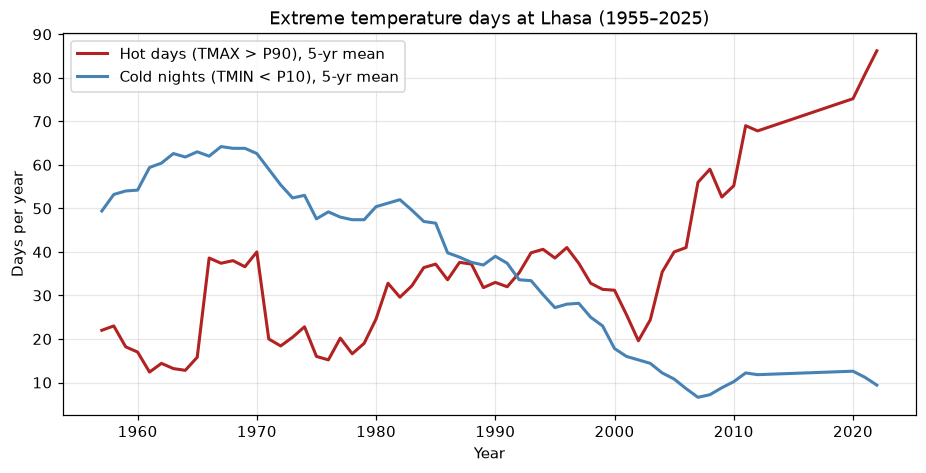

In [48]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(hot_days.index, hot_days.rolling(5, center=True).mean(),
        color="firebrick", lw=2, label="Hot days (TMAX > P90), 5-yr mean")
ax.plot(cold_nights.index, cold_nights.rolling(5, center=True).mean(),
        color="steelblue", lw=2, label="Cold nights (TMIN < P10), 5-yr mean")
ax.set_xlabel("Year")
ax.set_ylabel("Days per year")
ax.set_title("Extreme temperature days at Lhasa (1955–2025)")
ax.legend()
plt.savefig(os.path.join(FIG_DIR, "p4_3_extremes.png"))
plt.show()

In [49]:
dtr = (df["TMAX"] - df["TMIN"]).dropna()
print("日较差 DTR: 均值 {:.1f} °C,标准差 {:.1f} °C".format(dtr.mean(), dtr.std()))

# (1) TMAX vs TMIN
sub = df[["TMAX", "TMIN"]].dropna()
r1, p1 = stats.pearsonr(sub["TMAX"], sub["TMIN"])
print("\n(1) TMAX ~ TMIN:  r = {:.3f}, p = {:.2e}".format(r1, p1))

# (2) DTR 与年份(长期变化)
dtr_year = dtr.groupby(dtr.index.year).mean()
dtr_year = dtr_year.loc[dtr_year.index.isin(ok_years)]
r2, p2 = stats.pearsonr(dtr_year.index.values, dtr_year.values)
print("(2) DTR ~ 年份:   r = {:.3f}, p = {:.2e}  ({:+.3f} °C/10年)".format(
    r2, p2, stats.linregress(dtr_year.index.values, dtr_year.values).slope * 10))

# (3) 降水与气温
sub2 = df[["PRCP", "TMEAN"]].dropna()
r3p, p3p = stats.pearsonr(sub2["PRCP"], sub2["TMEAN"])
r3s, p3s = stats.spearmanr(sub2["PRCP"], sub2["TMEAN"])
print("(3) PRCP ~ TMEAN: Pearson r = {:.3f} (p = {:.2e});Spearman ρ = {:.3f} (p = {:.2e})".format(
    r3p, p3p, r3s, p3s))

日较差 DTR: 均值 14.3 °C,标准差 3.5 °C

(1) TMAX ~ TMIN:  r = 0.889, p = 0.00e+00
(2) DTR ~ 年份:   r = -0.347, p = 5.34e-03  (-0.104 °C/10年)
(3) PRCP ~ TMEAN: Pearson r = 0.251 (p = 0.00e+00);Spearman ρ = 0.401 (p = 0.00e+00)
